In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/nayanack/water-probability/water_potability.csv


load the dataset

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
df=pd.read_csv("/kaggle/input/datasets/nayanack/water-probability/water_potability.csv")
df.sample(30)

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
2502,6.574084,186.944211,22723.809959,6.212265,330.789695,385.018951,12.062534,72.595277,4.977324,0
3181,6.641174,191.916899,10220.712359,6.675081,380.363590,421.417352,12.243252,65.179927,3.154701,1
119,7.812804,196.583886,42550.841816,7.334648,NaN,442.545775,14.666917,NaN,6.204846,0
374,8.882684,135.523062,4857.253807,5.209779,NaN,532.336659,20.296274,20.337753,3.827921,1
1382,4.405327,169.742537,15039.710406,6.308198,352.917733,424.251162,14.441754,79.169597,4.086867,0
3269,11.491011,94.812545,37188.826022,9.263166,258.930600,439.893618,16.172755,41.558501,4.369264,1
1151,4.303575,227.007086,7323.302301,7.490508,326.695199,412.896404,12.906730,68.748918,2.010537,1
1784,9.252857,168.040751,50279.262429,5.905056,415.450810,400.003589,11.949854,62.256881,3.300586,0
546,3.410360,207.397473,49074.730407,5.667433,301.975011,351.520393,15.987370,86.639186,3.721766,0
2213,6.304972,249.082601,21046.448517,5.456273,NaN,334.178652,15.089083,52.791689,4.221306,0


Feature engineering part start here

In [3]:
df.describe()
df.columns

Index(['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity',
       'Organic_carbon', 'Trihalomethanes', 'Turbidity', 'Potability'],
      dtype='object')

In [4]:
df.isnull().sum()

ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

filling the missing values

In [5]:
cols = ['ph', 'Sulfate', 'Trihalomethanes']
df[cols] = df[cols].fillna(df[cols].median())
df = df.fillna(df.median(numeric_only=True))
df.isnull().sum()

ph                 0
Hardness           0
Solids             0
Chloramines        0
Sulfate            0
Conductivity       0
Organic_carbon     0
Trihalomethanes    0
Turbidity          0
Potability         0
dtype: int64

In [6]:

df["Hardness"].corr(df["Solids"])

np.float64(-0.04689936548817759)

<Axes: xlabel='Solids', ylabel='Hardness'>

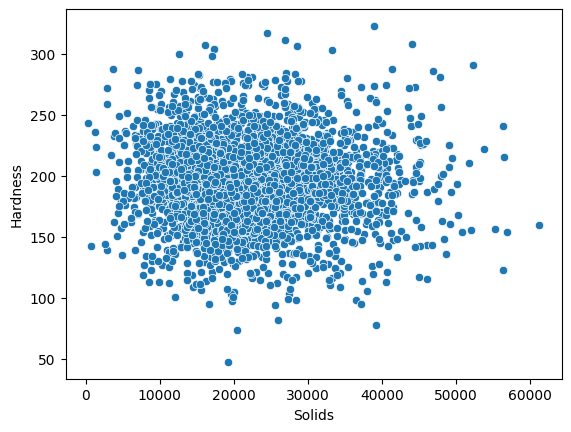

In [7]:
sns.scatterplot(data=df,x="Solids",y="Hardness")

outlier finding

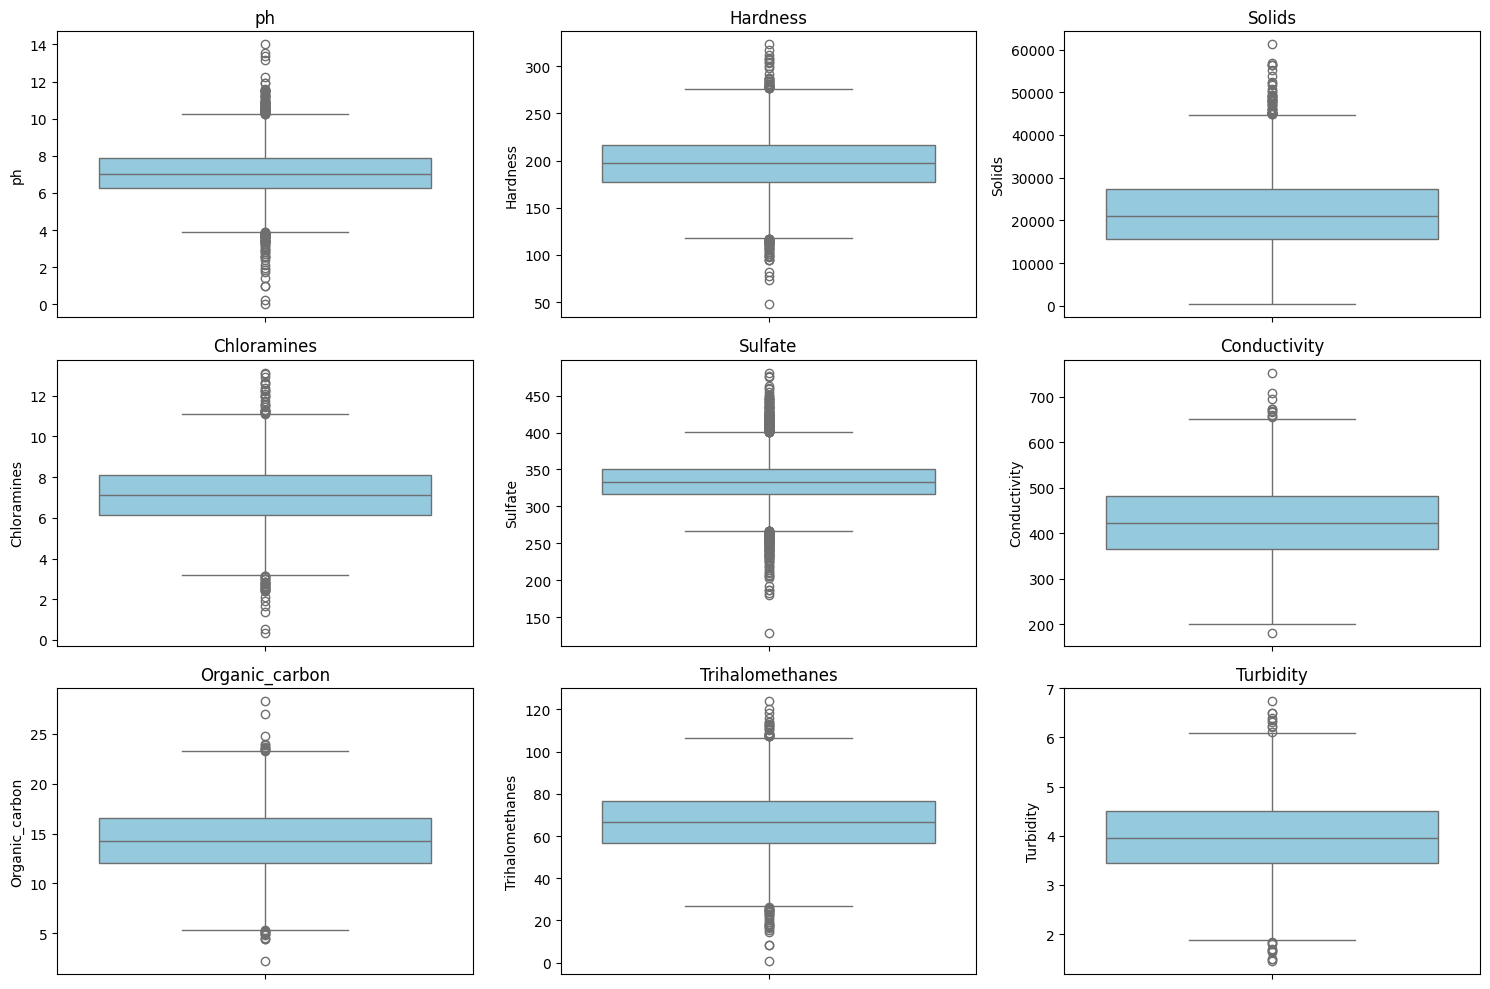

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

features = ['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate',
            'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity']

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.boxplot(y=df[col], ax=axes[i], color='skyblue')
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

Removing the outlier with capping method

In [9]:
features = ['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate',
            'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity']

df_capped = df.copy()

for col in features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df_capped[col] = df[col].clip(lower=lower, upper=upper)

In [10]:
df_capped.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,7.036752,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.889107,129.422921,18630.057858,6.635246,333.073546,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,333.073546,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


after remove the outlier, how the data distribution looks like

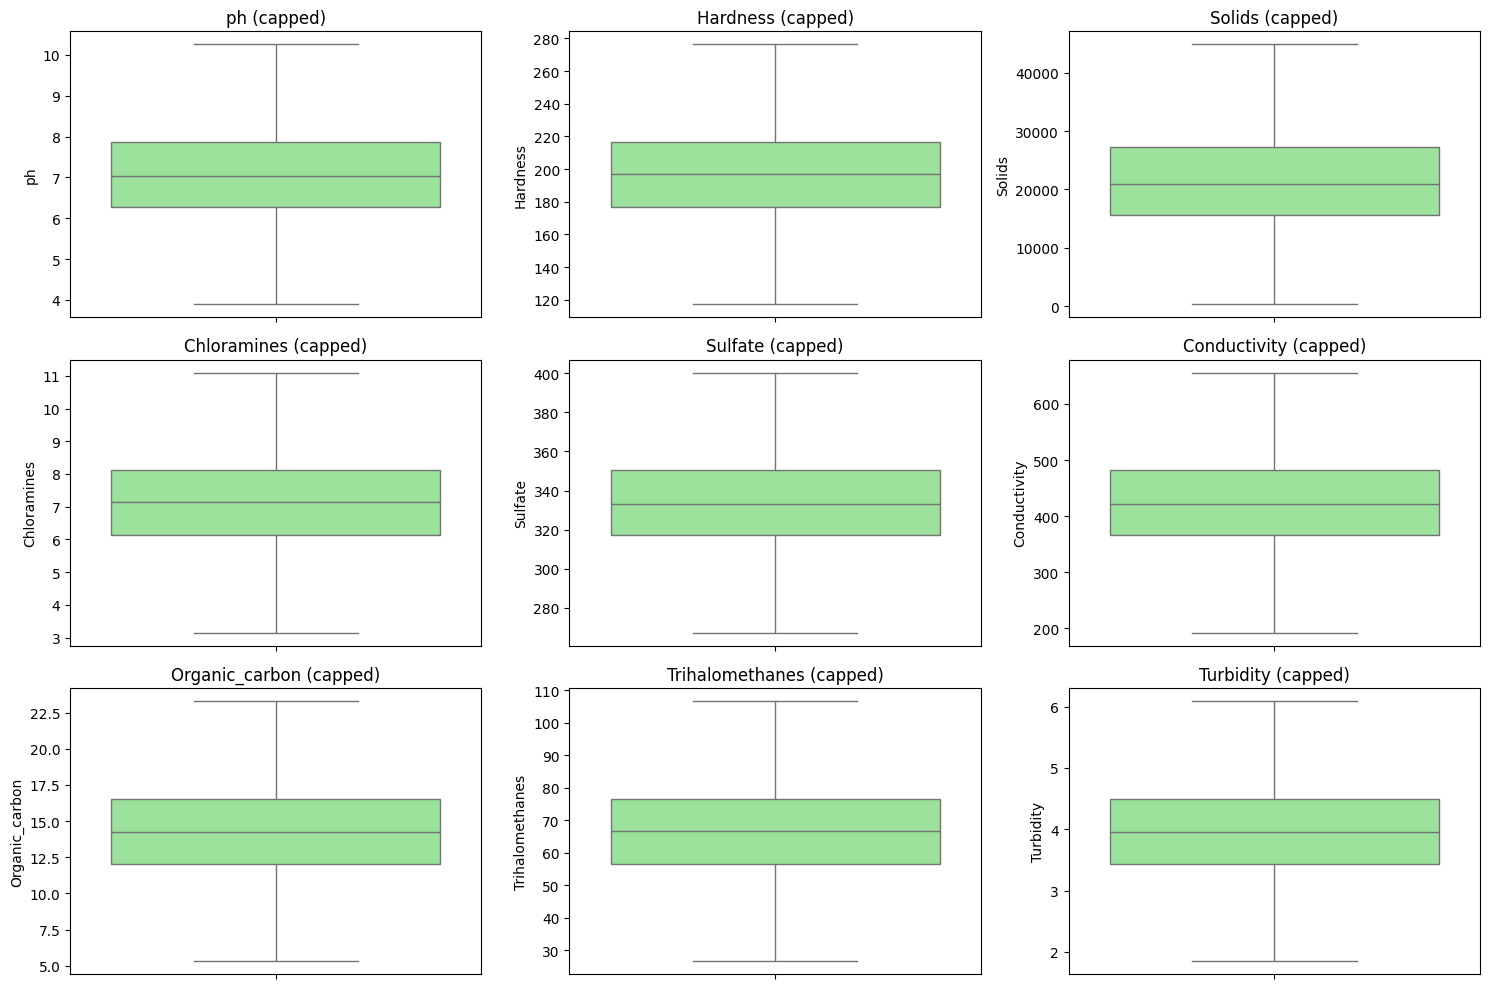

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.boxplot(y=df_capped[col], ax=axes[i], color='lightgreen')
    axes[i].set_title(f'{col} (capped)')

plt.tight_layout()
plt.show()

In [12]:
print(df[features].describe().loc[['min', 'max']].sum())
print(df_capped[features].describe().loc[['min', 'max']].sum())

ph                    14.000000
Hardness             370.556000
Solids             61548.138619
Chloramines           13.479000
Sulfate              610.030642
Conductivity         934.826374
Organic_carbon        30.500000
Trihalomethanes      124.738000
Turbidity              8.189000
dtype: float64
ph                    14.147722
Hardness             393.517994
Solids             45152.812484
Chloramines           14.242308
Sulfate              667.480394
Conductivity         847.526719
Organic_carbon        28.623453
Trihalomethanes      133.314265
Turbidity              7.940031
dtype: float64


In [13]:
df_capped.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,7.036752,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.889107,129.422921,18630.057858,6.635246,333.073546,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,333.073546,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


now i will try to transform it into boxcox and quantile transformation so that the skewness of data reduce

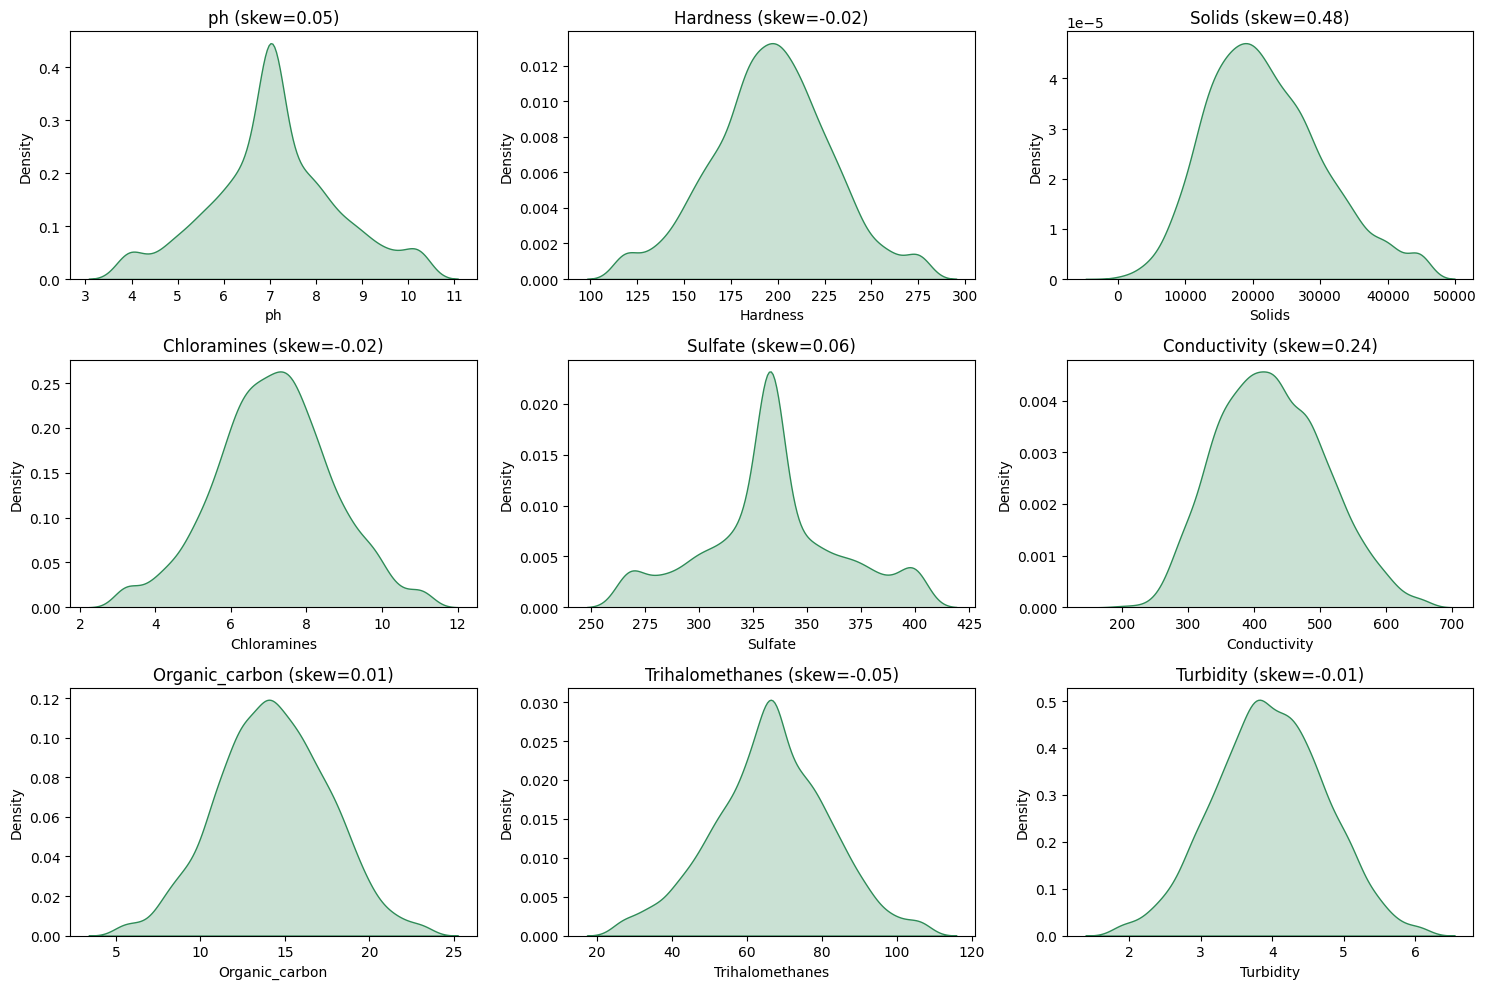

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

features = ['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate',
            'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity']

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.kdeplot(df_capped[col], ax=axes[i], fill=True, color='seagreen')
    axes[i].set_title(f'{col} (skew={df_capped[col].skew():.2f})')

plt.tight_layout()
plt.show()

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import PowerTransformer, QuantileTransformer

features = ['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate',
            'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity']

# Box-Cox needs all values > 0
print((df_capped[features] <= 0).sum())

# 1) Box-Cox
pt = PowerTransformer(method='box-cox', standardize=True)
df_boxcox = df_capped.copy()
df_boxcox[features] = pt.fit_transform(df_capped[features])

# 2) Quantile transform (to a normal distribution)
qt = QuantileTransformer(output_distribution='normal', n_quantiles=1000, random_state=42)
df_quantile = df_capped.copy()
df_quantile[features] = qt.fit_transform(df_capped[features])

ph                 0
Hardness           0
Solids             0
Chloramines        0
Sulfate            0
Conductivity       0
Organic_carbon     0
Trihalomethanes    0
Turbidity          0
dtype: int64


after transform cheak skewness

In [16]:
skew_table = pd.DataFrame({
    'Capped': df_capped[features].skew(),
    'Box-Cox': df_boxcox[features].skew(),
    'Quantile': df_quantile[features].skew()
})
print(skew_table.round(3))

# Box-Cox lambda for each column
print(dict(zip(features, pt.lambdas_.round(3))))

                 Capped  Box-Cox  Quantile
ph                0.055    0.004     0.105
Hardness         -0.025    0.001    -0.095
Solids            0.485    0.003     1.077
Chloramines      -0.018   -0.002    -0.022
Sulfate           0.056   -0.001     0.042
Conductivity      0.241   -0.012     0.267
Organic_carbon    0.009   -0.011    -0.028
Trihalomethanes  -0.052   -0.007    -0.093
Turbidity        -0.014   -0.014    -0.029
{'ph': np.float64(0.92), 'Hardness': np.float64(1.05), 'Solids': np.float64(0.568), 'Chloramines': np.float64(1.023), 'Sulfate': np.float64(0.798), 'Conductivity': np.float64(0.436), 'Organic_carbon': np.float64(0.971), 'Trihalomethanes': np.float64(1.062), 'Turbidity': np.float64(1.001)}


now i will take the quantile transformation just i perform more better
but there are some outlier still

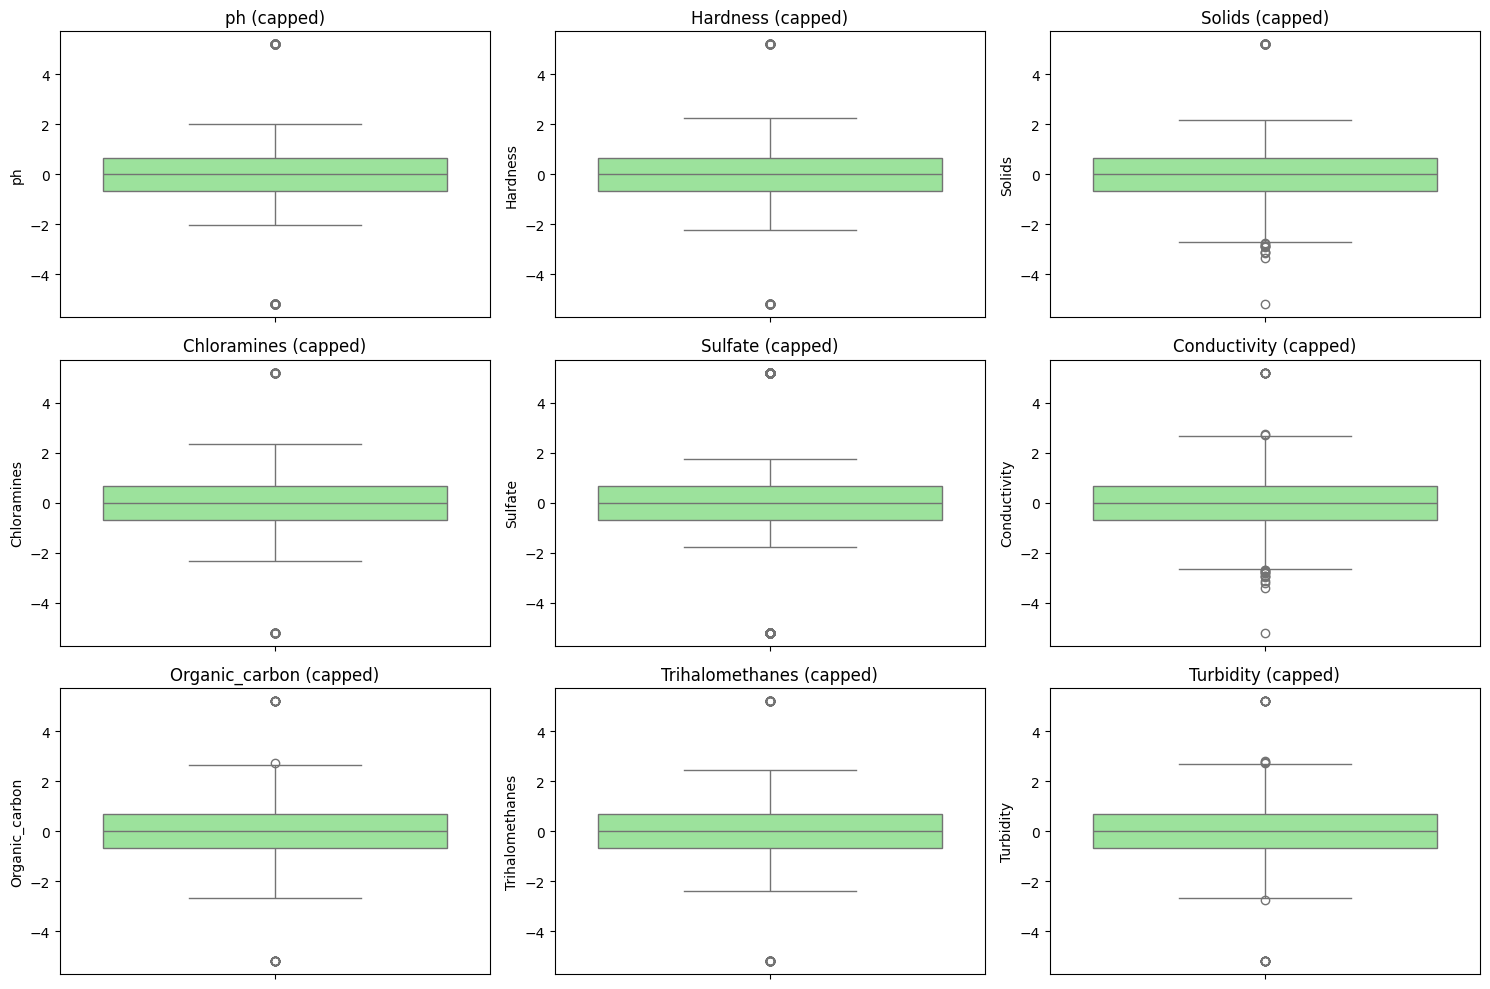

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.boxplot(y=df_quantile[col], ax=axes[i], color='lightgreen')
    axes[i].set_title(f'{col} (capped)')

plt.tight_layout()
plt.show()

again i remove the outlier

In [18]:
df_quantile_capped = df_quantile.copy()

for col in features:
    Q1 = df_quantile[col].quantile(0.25)
    Q3 = df_quantile[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df_quantile_capped[col] = df_quantile[col].clip(lower=lower, upper=upper)

In [19]:
df_quantile_capped.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,0.000000,0.278690,-0.014518,0.117197,1.044440,1.622936,-1.211475,1.352658,-1.258488,0
1,-2.701492,-1.938756,-0.275563,-0.318383,0.000000,1.970961,0.281667,-0.692145,0.675743,0
2,0.817502,0.904748,-0.131453,1.372103,0.000000,-0.036607,0.766000,-0.071573,-1.157362,0
3,0.959434,0.596870,0.120040,0.631622,0.819721,-0.711108,1.253964,2.119908,0.849808,0
4,1.378537,-0.532058,-0.362068,-0.381613,-0.832436,-0.278958,-0.833522,-2.096643,0.134696,0


all outlier are remove cheak!

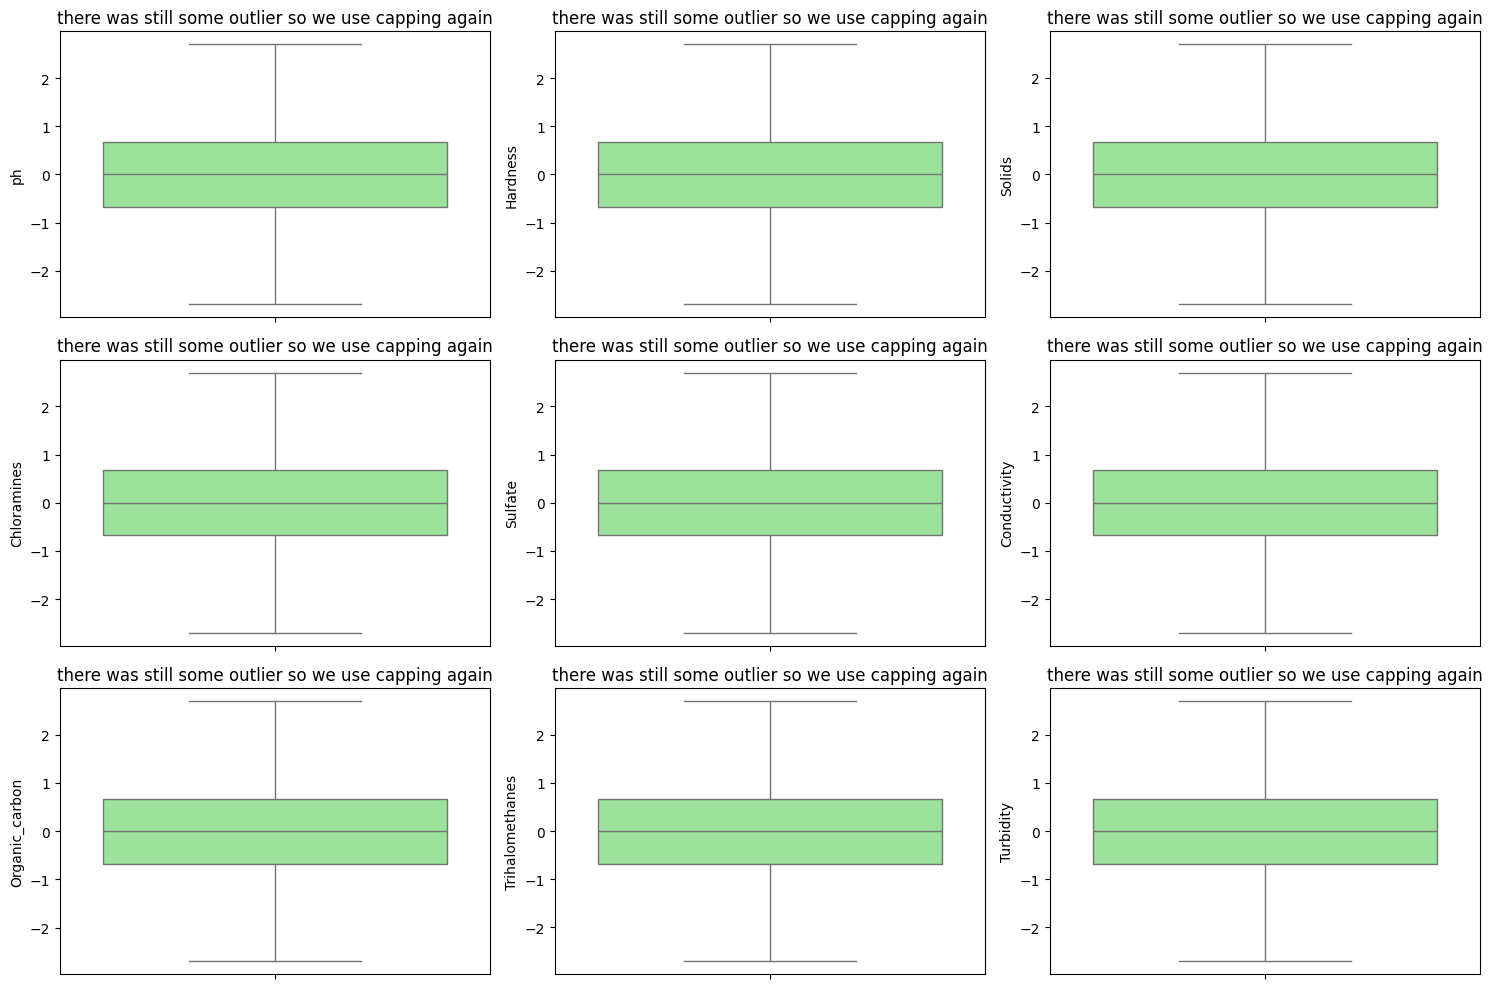

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.boxplot(y=df_quantile_capped[col], ax=axes[i], color='lightgreen')
    axes[i].set_title( 'there was still some outlier so we use capping again')

plt.tight_layout()
plt.show()

In [21]:
for col in features:
    n_clipped = (df_quantile_capped[col] != df_quantile_capped[col]).sum()
    print(f'{col}: {n_clipped} values clipped, skew = {df_quantile_capped[col].skew():.3f}')

ph: 0 values clipped, skew = 0.020
Hardness: 0 values clipped, skew = -0.010
Solids: 0 values clipped, skew = 0.051
Chloramines: 0 values clipped, skew = -0.001
Sulfate: 0 values clipped, skew = 0.015
Conductivity: 0 values clipped, skew = -0.000
Organic_carbon: 0 values clipped, skew = 0.001
Trihalomethanes: 0 values clipped, skew = -0.006
Turbidity: 0 values clipped, skew = -0.000


In [22]:
df_quantile_capped.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,0.000000,0.278690,-0.014518,0.117197,1.044440,1.622936,-1.211475,1.352658,-1.258488,0
1,-2.701492,-1.938756,-0.275563,-0.318383,0.000000,1.970961,0.281667,-0.692145,0.675743,0
2,0.817502,0.904748,-0.131453,1.372103,0.000000,-0.036607,0.766000,-0.071573,-1.157362,0
3,0.959434,0.596870,0.120040,0.631622,0.819721,-0.711108,1.253964,2.119908,0.849808,0
4,1.378537,-0.532058,-0.362068,-0.381613,-0.832436,-0.278958,-0.833522,-2.096643,0.134696,0


split into train and test and as a test data will take 30% data

In [23]:
from sklearn.model_selection import train_test_split

features = ['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate',
            'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity']

X = df_quantile_capped[features]
y = df_quantile_capped["Potability"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.1, random_state=42, stratify=y
)

print('X_train:', X_train.shape, ' X_test:', X_test.shape)
print('Train class ratio:\n', y_train.value_counts(normalize=True).round(3))
print('Test class ratio:\n', y_test.value_counts(normalize=True).round(3))

X_train: (2948, 9)  X_test: (328, 9)
Train class ratio:
 Potability
0    0.61
1    0.39
Name: proportion, dtype: float64
Test class ratio:
 Potability
0    0.61
1    0.39
Name: proportion, dtype: float64


now we try to reduce the dimension with the help of PCA(principal component analysis) 


at pca 8 or pca 9 variance almost same so there will be no profit if we reduce the dimension other hand pca will loss the information from dataset you can also see graph no.2

    PC  Explained_var  Cumulative
0  PC1         0.1337      0.1337
1  PC2         0.1261      0.2598
2  PC3         0.1175      0.3773
3  PC4         0.1136      0.4909
4  PC5         0.1102      0.6012
5  PC6         0.1073      0.7085
6  PC7         0.1060      0.8145
7  PC8         0.0983      0.9127
8  PC9         0.0873      1.0000
Components for 90% variance: 8
Components for 95% variance: 9


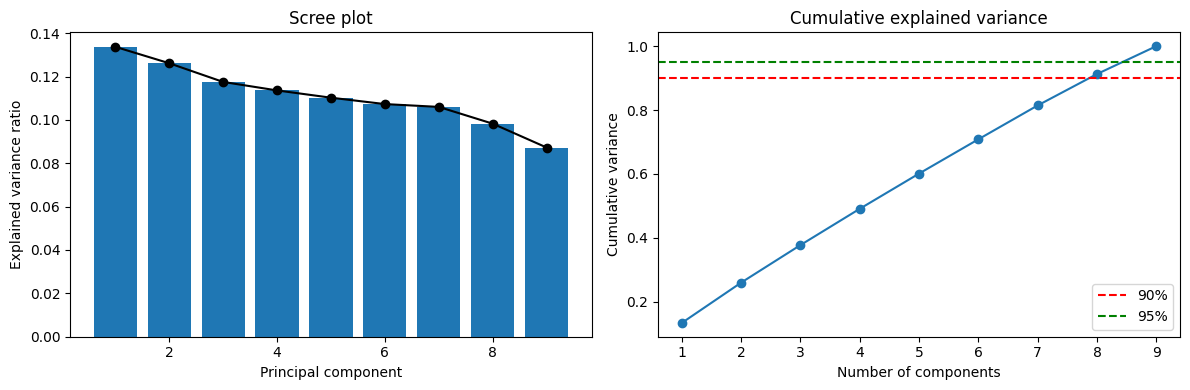

                   PC1    PC2    PC3    PC4
ph              -0.378  0.507  0.085 -0.112
Hardness        -0.143  0.571 -0.455 -0.125
Solids           0.688  0.068  0.126 -0.003
Chloramines     -0.259 -0.406 -0.286  0.276
Sulfate         -0.527 -0.315  0.336 -0.163
Conductivity     0.040  0.082  0.564 -0.003
Organic_carbon  -0.050  0.242  0.489  0.151
Trihalomethanes -0.010  0.022 -0.053  0.788
Turbidity        0.122 -0.288 -0.119 -0.474


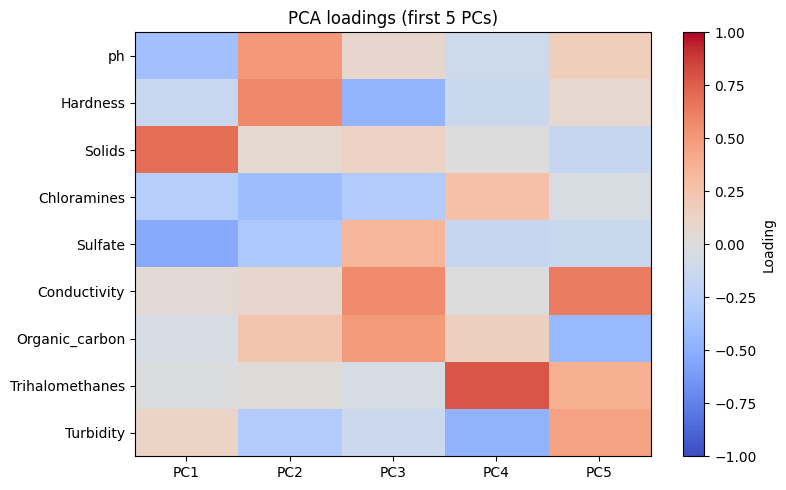

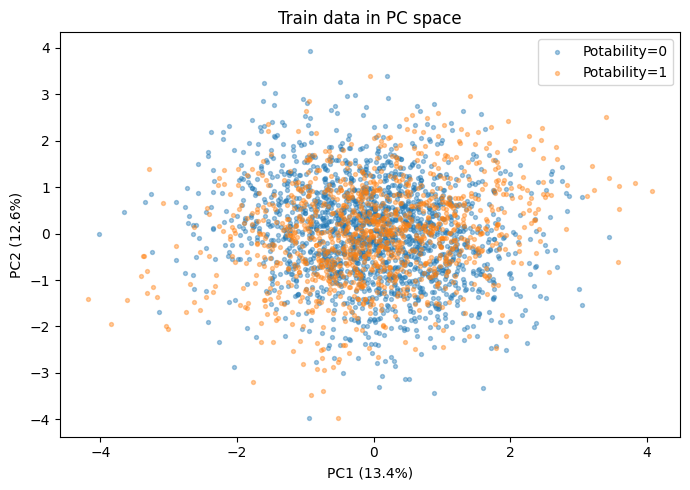

Reduced shape: (2948, 9) (328, 9)


In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Preprocess (fit on train only) and fit full PCA
prep = Pipeline([
    ('imp', SimpleImputer(strategy='median')),   # skip if no NaNs
    ('scaler', StandardScaler())
])
X_train_s = prep.fit_transform(X_train)
X_test_s  = prep.transform(X_test)

pca = PCA(random_state=42)
pca.fit(X_train_s)

# 2. Explained variance table
evr = pca.explained_variance_ratio_
cum = np.cumsum(evr)
var_df = pd.DataFrame({
    'PC': [f'PC{i+1}' for i in range(len(evr))],
    'Explained_var': evr.round(4),
    'Cumulative': cum.round(4)
})
print(var_df)
print('Components for 90% variance:', np.argmax(cum >= 0.90) + 1)
print('Components for 95% variance:', np.argmax(cum >= 0.95) + 1)

# 3. Scree + cumulative variance plot
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(range(1, len(evr)+1), evr)
ax[0].plot(range(1, len(evr)+1), evr, 'o-', color='k')
ax[0].set(xlabel='Principal component', ylabel='Explained variance ratio', title='Scree plot')
ax[1].plot(range(1, len(cum)+1), cum, 'o-')
ax[1].axhline(0.90, ls='--', color='r', label='90%')
ax[1].axhline(0.95, ls='--', color='g', label='95%')
ax[1].set(xlabel='Number of components', ylabel='Cumulative variance', title='Cumulative explained variance')
ax[1].legend()
plt.tight_layout(); plt.show()

loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=[f'PC{i+1}' for i in range(len(features))]
)
print(loadings.iloc[:, :4].round(3))

plt.figure(figsize=(8, 5))
plt.imshow(loadings.iloc[:, :5], cmap='coolwarm', vmin=-1, vmax=1, aspect='auto')
plt.colorbar(label='Loading')
plt.yticks(range(len(features)), features)
plt.xticks(range(5), [f'PC{i+1}' for i in range(5)])
plt.title('PCA loadings (first 5 PCs)')
plt.tight_layout(); plt.show()

Z_train = pca.transform(X_train_s)
plt.figure(figsize=(7, 5))
for cls, c in zip([0, 1], ['tab:blue', 'tab:orange']):
    m = (y_train.values == cls)
    plt.scatter(Z_train[m, 0], Z_train[m, 1], s=8, alpha=0.4, c=c, label=f'Potability={cls}')
plt.xlabel(f'PC1 ({evr[0]:.1%})'); plt.ylabel(f'PC2 ({evr[1]:.1%})')
plt.title('Train data in PC space'); plt.legend()
plt.tight_layout(); plt.show()

pca_95 = PCA(n_components=0.95, random_state=42).fit(X_train_s)
X_train_pca = pca_95.transform(X_train_s)
X_test_pca  = pca_95.transform(X_test_s)
print('Reduced shape:', X_train_pca.shape, X_test_pca.shape)

now we will perform hyperparameter tunning using optuna

In [25]:
import numpy as np
import pandas as pd
import optuna
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import (accuracy_score, roc_auc_score, f1_score,
                             classification_report)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective_rf(trial):
    params = dict(
        n_estimators=trial.suggest_int('n_estimators', 200, 800, step=100),
        max_depth=trial.suggest_int('max_depth', 4, 25),
        min_samples_split=trial.suggest_int('min_samples_split', 2, 30),
        min_samples_leaf=trial.suggest_int('min_samples_leaf', 1, 15),
        max_features=trial.suggest_categorical('max_features', ['sqrt', 'log2', 0.5]),
        max_samples=trial.suggest_float('max_samples', 0.5, 1.0),
        class_weight=trial.suggest_categorical('class_weight', [None, 'balanced', 'balanced_subsample']),
        ccp_alpha=trial.suggest_float('ccp_alpha', 1e-5, 5e-3, log=True),
        bootstrap=True, random_state=42, n_jobs=-1
    )
    model = RandomForestClassifier(**params)
    return cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc').mean()

study_rf = optuna.create_study(direction='maximize',
                               sampler=optuna.samplers.TPESampler(seed=42))
study_rf.optimize(objective_rf, n_trials=50, show_progress_bar=True)

print('Best CV AUC:', round(study_rf.best_value, 4))
print('Best params:', study_rf.best_params)

  0%|          | 0/50 [00:00<?, ?it/s]

Best CV AUC: 0.6804
Best params: {'n_estimators': 300, 'max_depth': 15, 'min_samples_split': 7, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_samples': 0.8775835862090338, 'class_weight': None, 'ccp_alpha': 0.0004282577498531884}


i will use all this hyperparameter in this 1)randomforest,2)gradientboosting,3)xgboosting


=== Random Forest ===
              precision    recall  f1-score   support

           0      0.706     0.890     0.788       200
           1      0.711     0.422     0.529       128

    accuracy                          0.707       328
   macro avg      0.708     0.656     0.659       328
weighted avg      0.708     0.707     0.687       328


=== Gradient Boosting ===
              precision    recall  f1-score   support

           0      0.697     0.920     0.793       200
           1      0.750     0.375     0.500       128

    accuracy                          0.707       328
   macro avg      0.723     0.647     0.647       328
weighted avg      0.718     0.707     0.679       328


=== XGBoost ===
              precision    recall  f1-score   support

           0      0.705     0.775     0.738       200
           1      0.583     0.492     0.534       128

    accuracy                          0.665       328
   macro avg      0.644     0.634     0.636       328
weighte

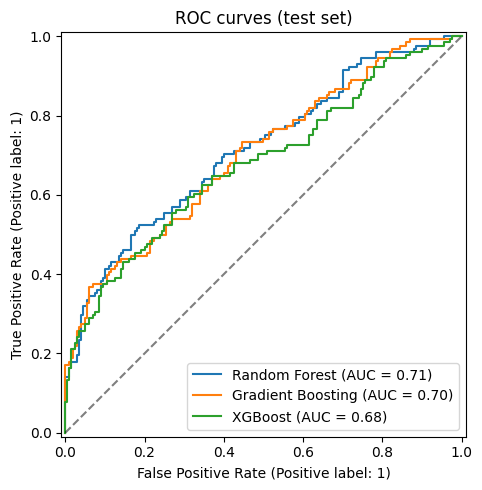

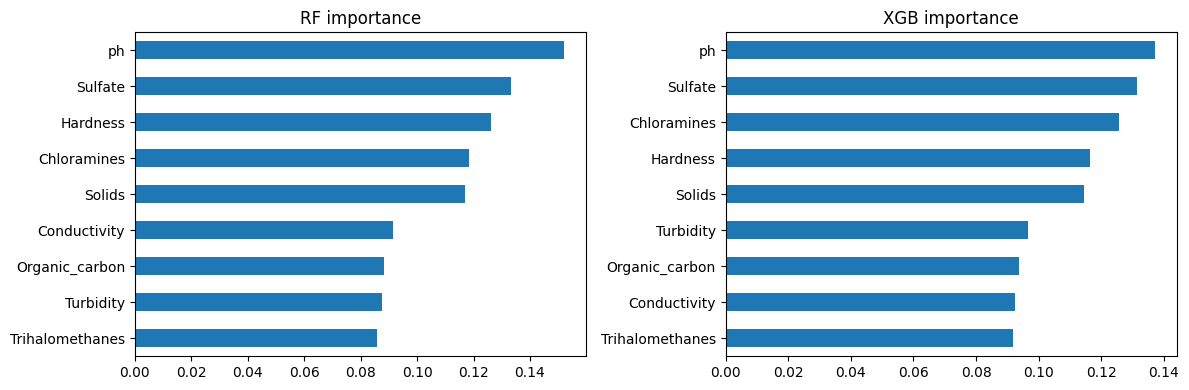

In [26]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import cross_val_score, StratifiedKFold


from sklearn.metrics import (accuracy_score, roc_auc_score, f1_score,
                             precision_score, recall_score,
                             classification_report, RocCurveDisplay)
#we build here randomforest
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rf = RandomForestClassifier(
    n_estimators=600,
    max_depth=14,
    min_samples_split=9,
    min_samples_leaf=2,
    max_features='log2',
    max_samples=0.9076876964052946,
    class_weight='balanced_subsample',
    ccp_alpha=1.396251588622418e-05,
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

# Gradient Boosting
gb = GradientBoostingClassifier(
    n_estimators=300,
    learning_rate=0.03,
    max_depth=4,
    min_samples_split=10,
    min_samples_leaf=5,
    subsample=0.8,
    max_features='sqrt',
    random_state=42
)

#  XGBoost
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()

xgb = XGBClassifier(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=5,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    gamma=1,
    reg_alpha=0.1,
    reg_lambda=1.0,
    scale_pos_weight=neg / pos,   
    tree_method='hist',
    eval_metric='auc',
    random_state=42,
    n_jobs=-1
)

models = {'Random Forest': rf, 'Gradient Boosting': gb, 'XGBoost': xgb}

#calculation cross validation
rows = []
for name, model in models.items():
    cv_auc = cross_val_score(model, X_train, y_train, cv=cv,
                             scoring='roc_auc', n_jobs=-1).mean()
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)

    print(f'\n=== {name} ===')
    print(classification_report(y_test, pred, digits=3))

    rows.append({
        'Model': name,
        'CV_AUC': cv_auc,
        'Test_AUC': roc_auc_score(y_test, proba),
        'Accuracy': accuracy_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
    })

res_df = pd.DataFrame(rows).set_index('Model').round(2)
print(res_df)

# ROC curves
fig, ax = plt.subplots(figsize=(6, 5))
for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
ax.set_title('ROC curves (test set)')
plt.tight_layout(); plt.show()

# Feature importance (RF and XGB)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
pd.Series(rf.feature_importances_, index=features).sort_values().plot.barh(ax=ax[0], title='RF importance')
pd.Series(xgb.feature_importances_, index=features).sort_values().plot.barh(ax=ax[1], title='XGB importance')
plt.tight_layout(); plt.show()

In [27]:
df_quantile_capped.isnull().sum()

ph                 0
Hardness           0
Solids             0
Chloramines        0
Sulfate            0
Conductivity       0
Organic_carbon     0
Trihalomethanes    0
Turbidity          0
Potability         0
dtype: int64

In [28]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from xgboost import XGBClassifier

rf = RandomForestClassifier(
    n_estimators=600, max_depth=14, min_samples_split=9, min_samples_leaf=2,
    max_features='log2', max_samples=0.9076876964052946,
    class_weight='balanced_subsample', ccp_alpha=1.396251588622418e-05,
    bootstrap=True, random_state=42, n_jobs=-1
)


gb = HistGradientBoostingClassifier(
    max_iter=300,                
    learning_rate=0.03,
    max_depth=4,
    min_samples_leaf=20,          
    l2_regularization=5.0,        
    class_weight='balanced',      
    early_stopping=False,         
    random_state=42
)

neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
xgb = XGBClassifier(
    n_estimators=500, learning_rate=0.03, max_depth=5, min_child_weight=3,
    subsample=0.8, colsample_bytree=0.8, gamma=1,
    reg_alpha=0.1,
    reg_lambda=5.0,              
    scale_pos_weight=neg / pos,
    tree_method='hist', eval_metric='auc',
    random_state=42, n_jobs=-1
)

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold, train_test_split
from sklearn.metrics import (accuracy_score, roc_auc_score, f1_score,
                             precision_score, recall_score,
                             classification_report, RocCurveDisplay)

# 1. Load data and split


X, y = df_quantile_capped[features], df_quantile_capped["Potability"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# 2. Cross-validation splitter
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 3. Models (the code you just pasted)
rf = RandomForestClassifier(
    n_estimators=600, max_depth=14, min_samples_split=9, min_samples_leaf=2,
    max_features='log2', max_samples=0.9076876964052946,
    class_weight='balanced_subsample', ccp_alpha=1.396251588622418e-05,
    bootstrap=True, random_state=42, n_jobs=-1
)

gb = HistGradientBoostingClassifier(
    max_iter=300, learning_rate=0.03, max_depth=4, min_samples_leaf=20,
    l2_regularization=5.0, class_weight='balanced',
    early_stopping=False, random_state=42
)

neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
xgb = XGBClassifier(
    n_estimators=500, learning_rate=0.03, max_depth=5, min_child_weight=3,
    subsample=0.8, colsample_bytree=0.8, gamma=1,
    reg_alpha=0.1, reg_lambda=5.0, scale_pos_weight=neg / pos,
    tree_method='hist', eval_metric='auc',
    random_state=42, n_jobs=-1
)

models = {'Random Forest': rf, 'Gradient Boosting': gb, 'XGBoost': xgb}

# 4. Train and evaluate
rows = []
for name, model in models.items():
    cv_auc = cross_val_score(model, X_train, y_train, cv=cv,
                             scoring='roc_auc', n_jobs=-1).mean()
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)

    print(f'\n=== {name} ===')
    print(classification_report(y_test, pred, digits=3))

    rows.append({
        'Model': name,
        'CV_AUC': cv_auc,
        'Test_AUC': roc_auc_score(y_test, proba),
        'Accuracy': accuracy_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
    })

res_df = pd.DataFrame(rows).set_index


=== Random Forest ===
              precision    recall  f1-score   support

           0      0.684     0.850     0.758       400
           1      0.623     0.387     0.477       256

    accuracy                          0.669       656
   macro avg      0.653     0.618     0.618       656
weighted avg      0.660     0.669     0.648       656


=== Gradient Boosting ===
              precision    recall  f1-score   support

           0      0.687     0.718     0.702       400
           1      0.525     0.488     0.506       256

    accuracy                          0.628       656
   macro avg      0.606     0.603     0.604       656
weighted avg      0.624     0.628     0.625       656


=== XGBoost ===
              precision    recall  f1-score   support

           0      0.678     0.718     0.697       400
           1      0.515     0.469     0.491       256

    accuracy                          0.620       656
   macro avg      0.597     0.593     0.594       656
weighte

In [30]:
rows = []
for name, model in models.items():
    cv_auc = cross_val_score(model, X_train, y_train, cv=cv,
                             scoring='roc_auc', n_jobs=-1).mean()
    model.fit(X_train, y_train)

    # Train and test predictions
    train_pred = model.predict(X_train)
    train_acc = accuracy_score(y_train, train_pred)

    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    test_acc = accuracy_score(y_test, pred)

    print(f'\n=== {name} ===')
    print(f'Train accuracy: {train_acc:.3f}')
    print(f'Test accuracy:  {test_acc:.3f}')
    print(f'Gap (train - test): {train_acc - test_acc:.3f}')
    print(classification_report(y_test, pred, digits=3))

    rows.append({
        'Model': name,
        'CV_AUC': cv_auc,
        'Test_AUC': roc_auc_score(y_test, proba),
        'Train_Acc': train_acc,
        'Test_Acc': test_acc,
        'F1': f1_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
    })

res_df = pd.DataFrame(rows).set_index('Model').round(3)
print(res_df)


=== Random Forest ===
Train accuracy: 0.973
Test accuracy:  0.669
Gap (train - test): 0.304
              precision    recall  f1-score   support

           0      0.684     0.850     0.758       400
           1      0.623     0.387     0.477       256

    accuracy                          0.669       656
   macro avg      0.653     0.618     0.618       656
weighted avg      0.660     0.669     0.648       656


=== Gradient Boosting ===
Train accuracy: 0.808
Test accuracy:  0.628
Gap (train - test): 0.180
              precision    recall  f1-score   support

           0      0.687     0.718     0.702       400
           1      0.525     0.488     0.506       256

    accuracy                          0.628       656
   macro avg      0.606     0.603     0.604       656
weighted avg      0.624     0.628     0.625       656


=== XGBoost ===
Train accuracy: 0.924
Test accuracy:  0.620
Gap (train - test): 0.304
              precision    recall  f1-score   support

           0  